# Evaluation of the three write paths
Reads the runs in `data/runs/aws` and the per-run results in `results`, and writes the report's tables to `results/report_tables` and its figures to `figures/aws/thesis_figures`. Run it with `make notebook`.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / "Makefile").exists() else Path.cwd().parent
DATA, RES = ROOT / "data/runs/aws", ROOT / "results"
OUT_T, OUT_F = RES / "report_tables", ROOT / "figures/aws/thesis_figures"
OUT_T.mkdir(parents=True, exist_ok=True); OUT_F.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"font.size": 11, "savefig.dpi": 300, "savefig.bbox": "tight"})
PATHS = ["P1", "P2", "P3"]
NAMES = {"P1": "P1 plain write", "P2": "P2 conditional write", "P3": "P3 idempotency-key write"}
COL = {"P1": "tab:blue", "P2": "tab:orange", "P3": "tab:green"}
RUNS = [1, 2, 3]
GROUPS = {"evaluation": [DATA / f"evaluation/run{i}" for i in RUNS],
          "sensitivity": [DATA / f"sensitivity/run{i}" for i in RUNS],
          "load 100": [DATA / f"load/w100/run{i}" for i in RUNS],
          "load 900": [DATA / f"load/w900/run{i}" for i in RUNS]}
RESDIR = {"evaluation": [RES / f"evaluation_runs/run{i}" for i in RUNS], "sensitivity": [RES / f"sensitivity_runs/run{i}" for i in RUNS],
          "load 100": [RES / f"load_runs/100_in_flight/run{i}" for i in RUNS],
          "load 900": [RES / f"load_runs/900_in_flight/run{i}" for i in RUNS]}

## 1. Integrity of the runs
Collects the integrity check of every run and the CloudWatch comparison of the evaluation and sensitivity runs.

In [2]:
rows = []
for group, runs in GROUPS.items():
    for i, run in enumerate(runs, 1):
        v = json.loads((run / "verify.json").read_text())
        cw = json.loads((run / "cloudwatch.json").read_text())["compare"] if group in ("evaluation", "sensitivity") else None
        rows.append({"group": group, "run": i, "requests": v["requests"], "deliveries": v["invocations"],
                     "missing": v["missing_deliveries"], "errors": v["errors"], "re-sent": v["resent_deliveries"],
                     "unplanned timeouts": v["unplanned_timeouts"], "requests never written": v["no_mutation"],
                     "check passed": v["ok"],
                     "CloudWatch invocations minus driver": cw["invocations_minus_driver"] if cw else "N/A",
                     "CloudWatch write units minus counted": cw["wcu_cloudwatch_minus_reported_plus_rule"] if cw else "N/A"})
integrity = pd.DataFrame(rows)
integrity.to_csv(OUT_T / "integrity.csv", index=False)
integrity

,group,run,requests,deliveries,missing,errors,re-sent,unplanned timeouts,requests never written,check passed,CloudWatch invocations minus driver,CloudWatch write units minus counted
0,evaluation,1,9000,24000,0,0,0,0,0,True,0.0,1.0
1,evaluation,2,9000,24000,0,0,0,0,0,True,0.0,-1.0
2,evaluation,3,9000,24000,0,0,0,0,0,True,0.0,-1.0
3,sensitivity,1,2000,7000,0,0,0,0,0,True,0.0,-3.0
4,sensitivity,2,2000,7000,0,0,0,0,0,True,0.0,-2.0
5,sensitivity,3,2000,7000,0,0,0,0,0,True,0.0,-2.0
6,load 100,1,9000,24000,0,0,0,1,0,False,N/A,N/A
7,load 100,2,9000,24000,0,0,0,0,0,True,N/A,N/A
8,load 100,3,9000,24000,0,0,0,1,0,False,N/A,N/A
9,load 900,1,9000,24000,0,0,0,1,1,False,N/A,N/A


## 1.1 Workload
Amounts of the synthetic payment requests, from the dataset and from each run's requests, rebuilt from the run's seed. The rebuilt request identifiers are checked against each stored schedule.

In [3]:
import sys, yaml
sys.path.insert(0, str(ROOT / "src"))
from driver import schedule
cfg = yaml.safe_load((ROOT / "config/experiment.yaml").read_text())
size = {"pilot": cfg["pilot"]["requests_per_path"], "evaluation": cfg["evaluation"]["requests_per_cell"],
        "sensitivity": cfg["evaluation"]["requests_per_cell"]}


# Amount statistics of one set of requests, in currency units
def amount_row(source, run, cents):
    a = pd.Series(cents) / 100
    return {"source": source, "run": run, "requests": len(a), "amount_mean": a.mean(), "amount_median": a.median(),
            "amount_min": a.min(), "amount_max": a.max()}


# Requests of a run rebuilt from its seed, checked against its stored schedule
def rebuilt(phase, run):
    reqs = schedule.build(cfg, phase, size[phase], json.loads((run / "run_info.json").read_text())["seed"])
    assert {r["request_id"] for r in reqs} == set(pd.read_csv(run / "schedule.csv")["request_id"])
    return reqs


rows = [amount_row("dataset", "N/A", schedule.amounts())]
for phase, runs in [("pilot", [DATA / "pilot"]), ("evaluation", GROUPS["evaluation"]), ("sensitivity", GROUPS["sensitivity"])]:
    for i, run in enumerate(runs, 1):
        rows.append(amount_row(phase, i, [r["payload"]["amount_cents"] for r in rebuilt(phase, run)]))
# each load run sends the requests of the evaluation run with the same seed
for group in ["load 100", "load 900"]:
    for ev_run, run in zip(GROUPS["evaluation"], GROUPS[group]):
        assert set(pd.read_csv(run / "schedule.csv")["request_id"]) == set(pd.read_csv(ev_run / "schedule.csv")["request_id"])
workload = pd.DataFrame(rows).round(2)
workload.to_csv(OUT_T / "workload.csv", index=False)
workload

,source,run,requests,amount_mean,amount_median,amount_min,amount_max
0,dataset,N/A,284807,88.35,22.00,0.0,25691.16
1,pilot,1,150,77.88,15.61,0.0,835.00
2,evaluation,1,9000,86.70,22.98,0.0,6669.00
3,evaluation,2,9000,90.56,21.84,0.0,6454.74
4,evaluation,3,9000,91.92,20.80,0.0,8790.26
5,sensitivity,1,2000,88.97,25.00,0.0,3033.40
6,sensitivity,2,2000,79.21,18.94,0.0,5934.90
7,sensitivity,3,2000,84.84,19.95,0.0,3848.01


## 2. Duplicate state mutation
Counts, from the DynamoDB stream, the retries that wrote the business item again, and checks the two expectations stated before the runs.

In [4]:
def cells(group):
    out = []
    for i, d in enumerate(RESDIR[group], 1):
        f = "sensitivity_cells.csv" if group == "sensitivity" else "cells.csv"
        c = pd.read_csv(d / f, na_values="N/A")
        c = c[c["phase"] == ("sensitivity" if group == "sensitivity" else "evaluation")].copy()
        c["run"] = i
        out.append(c)
    return pd.concat(out, ignore_index=True).rename(columns={"multiplicity": "deliveries"})

ev, se, l100, l900 = cells("evaluation"), cells("sensitivity"), cells("load 100"), cells("load 900")
dup = pd.concat([ev.assign(timeout="after the write"), se.assign(timeout="after P3's business-item write")])
dup = dup[dup["deliveries"] > 1][["timeout", "path", "deliveries", "run", "injected_retries", "dup_mutations", "dup_rate",
                                  "dup_ci_lo", "dup_ci_hi", "dup_cluster_ci_lo", "dup_request_ci_hi"]]
dup.to_csv(OUT_T / "duplicates.csv", index=False)
dup.pivot_table(index=["timeout", "path", "deliveries"], columns="run", values="dup_mutations")

run                                                  1       2       3
timeout                        path deliveries                        
after P3's business-item write P3   2           1000.0  1000.0  1000.0
                                    5           4000.0  4000.0  4000.0
after the write                P1   2           1000.0  1000.0  1000.0
                                    5           4000.0  4000.0  4000.0
                               P2   2              0.0     0.0     0.0
                                    5              0.0     0.0     0.0
                               P3   2              0.0     0.0     0.0
                                    5              0.0     0.0     0.0

In [5]:
exp = pd.concat([pd.read_csv(d / "expectations.csv", na_values="N/A").assign(run=i) for i, d in enumerate(RESDIR["evaluation"], 1)])
exp = exp[exp["expectation"].isin(["E1", "E2"])][["run", "expectation", "multiplicity", "subject", "estimate", "ci_lo", "rule", "decision"]]
exp.to_csv(OUT_T / "expectations.csv", index=False)
exp

,run,expectation,multiplicity,subject,estimate,ci_lo,rule,decision
0,1,E1,2,P1 duplicate rate,1.0,0.996173,Wilson and cluster-bootstrap lower bounds > 0.5,supported
1,1,E1,5,P1 duplicate rate,1.0,0.999041,Wilson and cluster-bootstrap lower bounds > 0.5,supported
2,1,E2,2,P2 reduction vs P1,1.0,0.992016,lower bound of the relative reduction > 0.90,supported
3,1,E2,2,P3 reduction vs P1,1.0,0.992016,lower bound of the relative reduction > 0.90,supported
4,1,E2,5,P2 reduction vs P1,1.0,0.998002,lower bound of the relative reduction > 0.90,supported
5,1,E2,5,P3 reduction vs P1,1.0,0.998002,lower bound of the relative reduction > 0.90,supported
0,2,E1,2,P1 duplicate rate,1.0,0.996173,Wilson and cluster-bootstrap lower bounds > 0.5,supported
1,2,E1,5,P1 duplicate rate,1.0,0.999041,Wilson and cluster-bootstrap lower bounds > 0.5,supported
2,2,E2,2,P2 reduction vs P1,1.0,0.992016,lower bound of the relative reduction > 0.90,supported
3,2,E2,2,P3 reduction vs P1,1.0,0.992016,lower bound of the relative reduction > 0.90,supported


### 2.1 Tracking item in the sensitivity runs
Counts, from the stream, the claims of a tracking item that was still in progress and the changes to completed.

In [6]:
rows = []
for i, run in enumerate(GROUPS["sensitivity"], 1):
    gt = {g["request_id"]: g for g in map(json.loads, (run / "ground_truth.jsonl").read_text().splitlines())}
    info = json.loads((run / "run_info.json").read_text())
    t0, t1 = info["t_start"] - 120, info["t_end"] + 120  # the run's window, two minutes each side, as in the analysis
    keys = [e for e in map(json.loads, (run / "stream.jsonl").read_text().splitlines())
            if e["kind"] == "idem_key" and e["request_id"] in gt and t0 <= e["approx_created_s"] <= t1]
    reclaims = sum(e["event"] == "MODIFY" and e["old_status"] == "IN_PROGRESS" and e["status"] == "IN_PROGRESS" for e in keys)
    completed = sum(e["event"] == "MODIFY" and e["status"] == "COMPLETED" for e in keys)
    rows.append({"run": i, "requests": len(gt), "retries": sum(g["multiplicity"] - 1 for g in gt.values()),
                 "claims of an in-progress key": reclaims, "changes to completed": completed})
claims = pd.DataFrame(rows)
claims.to_csv(OUT_T / "sensitivity_claims.csv", index=False)
claims

,run,requests,retries,claims of an in-progress key,changes to completed
0,1,2000,5000,5000,2000
1,2,2000,5000,5000,2000
2,3,2000,5000,5000,2000


## 3. Cost of each write path
Write capacity units per request, with each failed conditional write counted as one unit by rule, and the outcome of each request's last delivery.

In [7]:
def requests_of(group):
    return pd.concat([pd.read_csv(d / "requests.csv", na_values="N/A").assign(run=i) for i, d in enumerate(RESDIR[group], 1)])

req = requests_of("evaluation")
req = req[req["phase"] == "evaluation"].rename(columns={"multiplicity": "deliveries"})
outc = req.groupby(["path", "deliveries", "final_outcome"]).size().unstack(fill_value=0) / 3
cost = ev.groupby(["path", "deliveries"]).agg(
    capacity_reported=("capacity_reported_mean", "mean"), capacity_rule=("capacity_rule_mean", "mean"),
    capacity=("capacity_mean", "mean"), failed_condition_share=("ccf_per_retry", "mean"),
    successful_retry_rate=("successful_retry_rate", "mean"),
    latency_mean_min=("latency_mean_ms", "min"), latency_mean_max=("latency_mean_ms", "max"),
    latency_p95_min=("latency_p95_ms", "min"), latency_p95_max=("latency_p95_ms", "max")).round(3)
cost.to_csv(OUT_T / "cost.csv", na_rep="N/A")
cost

capacity_reported  capacity_rule  capacity  \
path deliveries                                               
P1   1                         1.0            NaN       1.0   
     2                         2.0            NaN       2.0   
     5                         5.0            NaN       5.0   
P2   1                         1.0            0.0       1.0   
     2                         1.0            1.0       2.0   
     5                         1.0            4.0       5.0   
P3   1                         3.0            0.0       3.0   
     2                         3.0            1.0       4.0   
     5                         3.0            4.0       7.0   

                 failed_condition_share  successful_retry_rate  \
path deliveries                                                  
P1   1                              NaN                    NaN   
     2                              NaN                    0.0   
     5                              NaN                    0.0   
P2   1                              NaN                    NaN   
     2                              1.0                    1.0   
     5                              1.0                    1.0   
P3   1                              NaN                    NaN   
     2                              1.0                    1.0   
     5                              1.0                    1.0   

                 latency_mean_min  latency_mean_max  latency_p95_min  \
path deliveries                                                        
P1   1                     61.816            63.861           79.743   
     2                   2434.218          2460.951         2560.450   
     5                   2427.698          2465.957         2543.042   
P2   1                     61.695            64.127           79.754   
     2                   2457.089          2488.697         2578.963   
     5                   2456.065          2488.248         2582.381   
P3   1                    136.896           138.997          159.819   
     2                   2457.132          2495.262         2581.306   
     5                   2456.641          2497.189         2580.969   

                 latency_p95_max  
path deliveries                   
P1   1                    79.935  
     2                  2562.200  
     5                  2562.869  
P2   1                    80.308  
     2                  2601.561  
     5                  2599.340  
P3   1                   160.615  
     2                  2601.688  
     5                  2602.374

In [8]:
outc

final_outcome    APPLIED  REPLAYED  SUPPRESSED
path deliveries                               
P1   1            1000.0       0.0         0.0
     2            1000.0       0.0         0.0
     5            1000.0       0.0         0.0
P2   1            1000.0       0.0         0.0
     2               0.0       0.0      1000.0
     5               0.0       0.0      1000.0
P3   1            1000.0       0.0         0.0
     2               0.0    1000.0         0.0
     5               0.0    1000.0         0.0

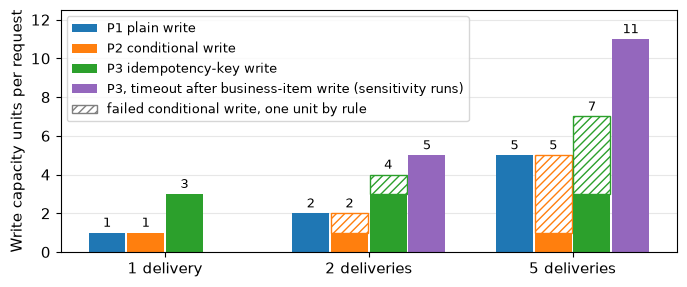

In [9]:
from matplotlib.patches import Patch
DELIV = [1, 2, 5]
XL = ["1 delivery", "2 deliveries", "5 deliveries"]
series = [("P1", ev, COL["P1"], NAMES["P1"]), ("P2", ev, COL["P2"], NAMES["P2"]), ("P3", ev, COL["P3"], NAMES["P3"]), ("P3", se, "tab:purple", "P3, timeout after business-item write (sensitivity runs)")]
fig, ax = plt.subplots(figsize=(7.0, 3.0))
w = 0.19
for j, (p, src, c, lab) in enumerate(series):
    g = src[src["path"] == p].groupby("deliveries")[["capacity_reported_mean", "capacity_rule_mean"]].mean().fillna(0)
    for k, d in enumerate(DELIV):
        if d not in g.index:
            continue
        rep, rule = g.loc[d, "capacity_reported_mean"], g.loc[d, "capacity_rule_mean"]
        x = k + (j - 1.5) * w
        ax.bar(x, rep, w * 0.95, color=c, label=lab if k == (1 if j == 3 else 0) else None)
        if rule:
            ax.bar(x, rule, w * 0.95, bottom=rep, color="white", edgecolor=c, hatch="////")
        ax.text(x, rep + rule + 0.15, f"{rep + rule:.0f}", ha="center", va="bottom", fontsize=9)
ax.set_xticks(range(3), XL); ax.set_ylabel("Write capacity units per request")
ax.set_ylim(0, 12.5); ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)
h, l = ax.get_legend_handles_labels()
ax.legend(h + [Patch(facecolor="white", edgecolor="gray", hatch="////")], l + ["failed conditional write, one unit by rule"], loc="upper left", fontsize=9)
fig.tight_layout(); fig.savefig(OUT_F / "capacity.png"); plt.show()

### 3.1 Latency between write paths
Tests the final-delivery latency of each pair of write paths with one request in flight, per run. `diff` is the first path minus the second.

In [10]:
tests = pd.concat([pd.read_csv(d / "latency_tests.csv", na_values="N/A").assign(run=i) for i, d in enumerate(RESDIR["evaluation"], 1)])
tests = tests[tests["metric"] == "latency_ms"].rename(columns={"multiplicity": "deliveries"})
tests.to_csv(OUT_T / "latency_tests.csv", index=False)

In [11]:
tests.pivot_table(index=["deliveries", "comparison"], columns="run", values=["diff", "p_holm", "effect"]).round(3)

diff                 effect               p_holm  \
run                         1       2       3      1      2      3      1   
deliveries comparison                                                       
1          P1 vs P2     0.059  -0.007  -0.074  0.026 -0.003 -0.026  0.904   
           P1 vs P3   -79.057 -79.477 -79.125 -0.998 -0.997 -0.997  0.000   
           P2 vs P3   -79.099 -79.479 -78.971 -0.996 -0.996 -0.995  0.000   
2          P1 vs P2   -21.175 -28.223 -27.845 -0.174 -0.258 -0.262  0.000   
           P1 vs P3   -23.028 -35.394 -35.977 -0.182 -0.305 -0.321  0.000   
           P2 vs P3    -0.511  -3.911  -2.736 -0.014 -0.052 -0.055  0.904   
5          P1 vs P2   -28.216 -20.361 -20.476 -0.206 -0.196 -0.201  0.000   
           P1 vs P3   -31.293 -28.529 -30.644 -0.231 -0.258 -0.273  0.000   
           P2 vs P3    -1.603  -7.332  -8.910 -0.027 -0.064 -0.081  0.904   

                                     
run                        2      3  
deliveries comparison                
1          P1 vs P2    0.907  0.316  
           P1 vs P3    0.000  0.000  
           P2 vs P3    0.000  0.000  
2          P1 vs P2    0.000  0.000  
           P1 vs P3    0.000  0.000  
           P2 vs P3    0.089  0.065  
5          P1 vs P2    0.000  0.000  
           P1 vs P3    0.000  0.000  
           P2 vs P3    0.041  0.005

## 4. Agreement between runs
Smallest and largest value of the three evaluation runs per write path and number of deliveries.

In [12]:
agg = pd.read_csv(RES / "evaluation_runs/all_runs/evaluation_runs_aggregate.csv", na_values="N/A")
agg[["path", "multiplicity", "dup_rate_min", "dup_rate_max", "capacity_min", "capacity_max", "latency_min", "latency_max"]]

,path,multiplicity,dup_rate_min,dup_rate_max,capacity_min,capacity_max,latency_min,latency_max
0,P1,1,NaN,NaN,1.0,1.0,61.816140,63.860572
1,P1,2,1.0,1.0,2.0,2.0,2434.217999,2460.950920
2,P1,5,1.0,1.0,5.0,5.0,2427.697904,2465.956599
3,P2,1,NaN,NaN,1.0,1.0,61.695173,64.127495
4,P2,2,0.0,0.0,2.0,2.0,2457.089236,2488.697350
5,P2,5,0.0,0.0,5.0,5.0,2456.064917,2488.247634
6,P3,1,NaN,NaN,3.0,3.0,136.896369,138.996833
7,P3,2,0.0,0.0,4.0,4.0,2457.131737,2495.261518
8,P3,5,0.0,0.0,7.0,7.0,2456.641140,2497.189316


## 5. Requests in flight
Compares duplicates, mean latency and cold starts with 1, 100 and 900 requests in flight (same seeds and requests as the evaluation runs), and draws the mean latency at each level.

In [13]:
lev = {1: ev, 100: l100, 900: l900}
rows = []
for level, c in lev.items():
    for _, r in c.iterrows():
        rows.append({"requests in flight": level, "run": r["run"], "path": r["path"], "deliveries": r["deliveries"],
                     "retries": r["injected_retries"], "duplicates": r["dup_mutations"], "dup_rate": r["dup_rate"],
                     "latency_mean_ms": r["latency_mean_ms"], "latency_warm_mean_ms": r["latency_warm_mean_ms"],
                     "cold_final_share": r["cold_final_share"], "requests_never_written": r["no_mutation"]})
load = pd.DataFrame(rows)
load.to_csv(OUT_T / "load.csv", index=False, na_rep="N/A")
load[load["deliveries"] > 1].pivot_table(index=["path", "deliveries"], columns="requests in flight",
                                        values="duplicates", aggfunc=["min", "max"])

min               max            
requests in flight   1     100   900   1     100   900
path deliveries                                       
P1   2              1000  1000  1000  1000  1000  1000
     5              4000  3999  4000  4000  4000  4000
P2   2                 0     0     0     0     0     0
     5                 0     0     0     0     0     0
P3   2                 0     0     0     0     0     0
     5                 0     0     0     0     0     0

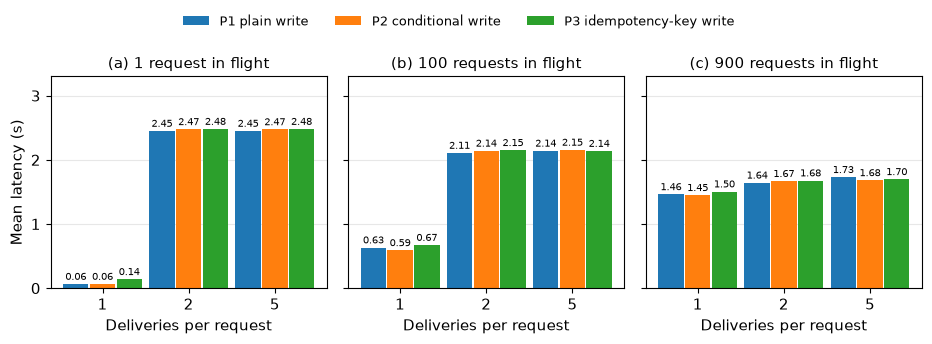

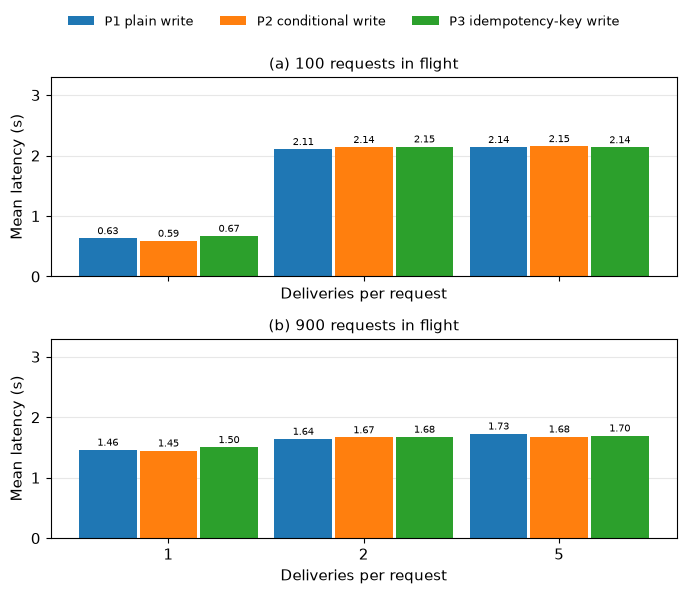

In [14]:
def latency_bars(ax, src):
    w = 0.31
    for j, p in enumerate(PATHS):
        for k, d in enumerate(DELIV):
            v = src[(src["path"] == p) & (src["deliveries"] == d)]["latency_mean_ms"].mean()  # mean of the three runs
            x = k + (j - 1) * w
            ax.bar(x, v / 1000, w * 0.95, color=COL[p], label=NAMES[p] if k == 0 else None)
            ax.text(x, v / 1000 + 0.03, f"{v / 1000:.2f}", ha="center", va="bottom", fontsize=7)
    ax.set_xticks(range(3), ["1", "2", "5"]); ax.set_xlabel("Deliveries per request"); ax.set_ylim(0, 3.3); ax.set_ylabel("Mean latency (s)")
    ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)

fig, axes = plt.subplots(1, 3, figsize=(9.6, 3.1), sharey=True)
for ax, level, t in zip(axes, [1, 100, 900], ["(a) 1 request in flight", "(b) 100 requests in flight", "(c) 900 requests in flight"]):
    latency_bars(ax, load[load["requests in flight"] == level]); ax.set_title(t, fontsize=10.5)
for ax in axes[1:]:
    ax.set_ylabel("")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, fontsize=9.5, frameon=False)
fig.tight_layout(); fig.savefig(OUT_F / "latency.png"); plt.show()

fig, axes = plt.subplots(2, 1, figsize=(7.0, 5.6), sharex=True)
for ax, level, t in zip(axes, [100, 900], ["(a) 100 requests in flight", "(b) 900 requests in flight"]):
    latency_bars(ax, load[load["requests in flight"] == level]); ax.set_title(t, fontsize=11)
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, fontsize=9.5, frameon=False)
fig.tight_layout(); fig.savefig(OUT_F / "load.png"); plt.show()

Distribution of the final-delivery latency, with one delivery and one request in flight, and with five deliveries and 900 requests in flight, and the 95th percentile and cold-start share at each level (smallest and largest of the three runs).

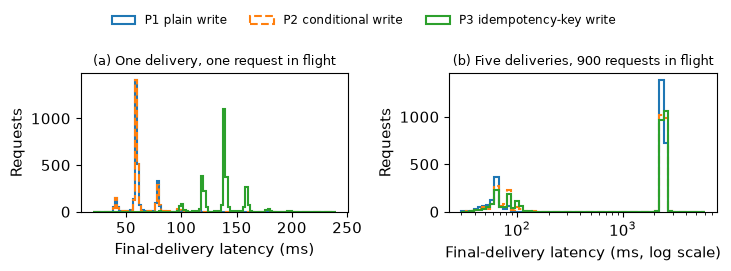

,path,deliveries,requests in flight,latency_p95_min,latency_p95_max,cold_final_share_min,cold_final_share_max
0,P1,1,1,79.74295,79.93505,0.000,0.001
1,P1,1,100,2483.42320,2502.75360,0.233,0.243
2,P1,1,900,2533.77195,2853.81670,0.542,0.596
3,P1,2,1,2560.44970,2562.19965,1.000,1.000
4,P1,2,100,2541.93350,2561.79615,0.853,0.863
5,P1,2,900,2508.95180,2546.72245,0.658,0.683
6,P1,5,1,2543.04210,2562.86865,1.000,1.000
7,P1,5,100,2542.65950,2561.40490,0.868,0.878
8,P1,5,900,2486.69360,2543.64675,0.668,0.730
9,P2,1,1,79.75435,80.30780,0.000,0.001


In [15]:
def final_latency(group, deliveries):
    r = pd.concat([pd.read_csv(d / "requests.csv", na_values="N/A") for d in RESDIR[group]])
    return r[r["multiplicity"] == deliveries]

fig, (a, b) = plt.subplots(1, 2, figsize=(7.4, 2.4))
panels = [(a, "evaluation", 1, np.arange(20, 242, 2), "(a) One delivery, one request in flight"),
          (b, "load 900", 5, np.logspace(np.log10(30), np.log10(6000), 60), "(b) Five deliveries, 900 requests in flight")]
for ax, group, d, bins, t in panels:
    r = final_latency(group, d)
    for p in PATHS:
        ax.hist(r[r["path"] == p]["latency_ms"], bins=bins, histtype="step", linewidth=1.5, color=COL[p],
                linestyle="--" if p == "P2" else "-", label=NAMES[p])  # dashed P2 shows its overlap with P1
    ax.set_title(t, fontsize=9); ax.set_ylabel("Requests")
a.set_xlabel("Final-delivery latency (ms)")
b.set_xscale("log"); b.set_xlabel("Final-delivery latency (ms, log scale)")
fig.legend(*a.get_legend_handles_labels(), loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, fontsize=8.5, frameon=False)
fig.tight_layout(); fig.savefig(OUT_F / "latency_hist.png"); plt.show()

p95 = pd.concat([c.assign(level=lvl) for lvl, c in lev.items()])
p95 = (p95.groupby(["path", "deliveries", "level"])
          .agg(latency_p95_min=("latency_p95_ms", "min"), latency_p95_max=("latency_p95_ms", "max"),
               cold_final_share_min=("cold_final_share", "min"), cold_final_share_max=("cold_final_share", "max"))
          .reset_index().rename(columns={"level": "requests in flight"}))
p95.to_csv(OUT_T / "latency_p95.csv", index=False)
p95

In [16]:
load.groupby(["requests in flight", "path", "deliveries"])[["latency_mean_ms", "latency_warm_mean_ms", "cold_final_share"]].mean().round(3)

latency_mean_ms  latency_warm_mean_ms  \
requests in flight path deliveries                                          
1                  P1   1                    62.816                62.073   
                        2                  2448.530                   NaN   
                        5                  2448.690                   NaN   
                   P2   1                    63.126                62.405   
                        2                  2474.516                   NaN   
                        5                  2472.776                   NaN   
                   P3   1                   137.612               136.296   
                        2                  2478.683                   NaN   
                        5                  2478.174                   NaN   
100                P1   1                   631.182                62.370   
                        2                  2105.245                61.132   
                        5                  2138.924                60.557   
                   P2   1                   588.575                61.731   
                        2                  2138.991                71.207   
                        5                  2153.664                69.468   
                   P3   1                   670.179               134.854   
                        2                  2148.418                72.607   
                        5                  2135.442                74.626   
900                P1   1                  1460.504               117.838   
                        2                  1640.861                62.395   
                        5                  1727.767                61.123   
                   P2   1                  1447.315               128.110   
                        2                  1665.801                75.449   
                        5                  1679.011                71.744   
                   P3   1                  1503.678               183.036   
                        2                  1675.585                77.383   
                        5                  1695.393                76.159   

                                    cold_final_share  
requests in flight path deliveries                    
1                  P1   1                      0.000  
                        2                      1.000  
                        5                      1.000  
                   P2   1                      0.000  
                        2                      1.000  
                        5                      1.000  
                   P3   1                      0.001  
                        2                      1.000  
                        5                      1.000  
100                P1   1                      0.239  
                        2                      0.859  
                        5                      0.872  
                   P2   1                      0.221  
                        2                      0.863  
                        5                      0.871  
                   P3   1                      0.224  
                        2                      0.866  
                        5                      0.861  
900                P1   1                      0.572  
                        2                      0.666  
                        5                      0.705  
                   P2   1                      0.564  
                        2                      0.668  
                        5                      0.676  
                   P3   1                      0.560  
                        2                      0.670  
                        5                      0.681

Deliveries that timed out without a scheduled timeout, with their round trip and whether the function left a record.

In [17]:
flag = []
for group in ["load 100", "load 900"]:
    for i, run in enumerate(GROUPS[group], 1):
        for line in (run / "deliveries.jsonl").read_text().splitlines():
            d = json.loads(line)
            if d["status"] == "timeout" and d["inject"] == "none":
                flag.append({"group": group, "run": i, "path": d["path"], "deliveries": d["multiplicity"],
                             "delivery": d["delivery"], "round_trip_ms": d["rtt_ms"], "function_record": d.get("exec_id") is not None})
pd.DataFrame(flag)

,group,run,path,deliveries,delivery,round_trip_ms,function_record
0,load 100,1,P1,5,5,3672.470,False
1,load 100,3,P1,5,5,3665.509,False
2,load 900,1,P2,1,1,3967.645,False
